In [1]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

In [3]:
X_train.shape

(50000, 32, 32, 3)

In [4]:
X_train[0]

array([[[ 59,  62,  63],
        [ 43,  46,  45],
        [ 50,  48,  43],
        ...,
        [158, 132, 108],
        [152, 125, 102],
        [148, 124, 103]],

       [[ 16,  20,  20],
        [  0,   0,   0],
        [ 18,   8,   0],
        ...,
        [123,  88,  55],
        [119,  83,  50],
        [122,  87,  57]],

       [[ 25,  24,  21],
        [ 16,   7,   0],
        [ 49,  27,   8],
        ...,
        [118,  84,  50],
        [120,  84,  50],
        [109,  73,  42]],

       ...,

       [[208, 170,  96],
        [201, 153,  34],
        [198, 161,  26],
        ...,
        [160, 133,  70],
        [ 56,  31,   7],
        [ 53,  34,  20]],

       [[180, 139,  96],
        [173, 123,  42],
        [186, 144,  30],
        ...,
        [184, 148,  94],
        [ 97,  62,  34],
        [ 83,  53,  34]],

       [[177, 144, 116],
        [168, 129,  94],
        [179, 142,  87],
        ...,
        [216, 184, 140],
        [151, 118,  84],
        [123,  92,  72]]

In [5]:
y_train[0]
y_train = y_train.reshape(-1, )
y_train.shape

(50000,)

In [6]:
classes = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

In [7]:
def plot_sample(X, y, index):
    plt.figure(figsize=(15,2))
    plt.imshow(X[index])
    plt.xlabel(classes[y[index]])

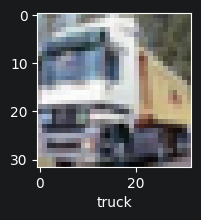

In [8]:
plot_sample(X_train, y_train, 1)

In [9]:
X_train = X_train / 255
X_test = X_test / 255

In [10]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(32, 32, 3)),
    keras.layers.Dense(3000, activation='relu'),
    keras.layers.Dense(1000, activation='relu'),
    keras.layers.Dense(500, activation='relu'),
    keras.layers.Dense(10, activation='sigmoid')
])

model.compile(
    optimizer='SGD',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(X_train, y_train, epochs=5)

D:\Data Science\.venv\lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 67s 43ms/step - accuracy: 0.3474 - loss: 1.8202
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 66s 42ms/step - accuracy: 0.4240 - loss: 1.6221
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 69s 44ms/step - accuracy: 0.4565 - loss: 1.5345
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 69s 44ms/step - accuracy: 0.4799 - loss: 1.4704
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 69s 44ms/step - accuracy: 0.4965 - loss: 1.4188


In [11]:
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.4560 - loss: 1.5242


[1.5242218971252441, 0.4560000002384186]

In [12]:
y_pred = model.predict(X_test)
y_pred

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step


array([[0.21911332, 0.28438184, 0.79973376, ..., 0.0443674 , 0.26092276,
        0.11700661],
       [0.8031491 , 0.96698076, 0.3205048 , ..., 0.03822554, 0.95728403,
        0.99227947],
       [0.91257554, 0.95145667, 0.29227826, ..., 0.08927602, 0.96383184,
        0.95322007],
       ...,
       [0.0611278 , 0.05946455, 0.88366085, ..., 0.3868576 , 0.26590315,
        0.13623056],
       [0.27981213, 0.2346838 , 0.8662589 , ..., 0.15244237, 0.07681765,
        0.2408292 ],
       [0.2867419 , 0.170855  , 0.68896574, ..., 0.87408984, 0.11084507,
        0.2887543 ]], shape=(10000, 10), dtype=float32)

In [13]:
import numpy as np
from sklearn.metrics import classification_report
y_pred_classes = [np.argmax(element) for element in y_pred]

print(classification_report(y_test, y_pred_classes))

              precision    recall  f1-score   support

           0       0.75      0.29      0.42      1000
           1       0.66      0.56      0.61      1000
           2       0.34      0.40      0.37      1000
           3       0.43      0.15      0.22      1000
           4       0.38      0.38      0.38      1000
           5       0.47      0.27      0.35      1000
           6       0.31      0.83      0.45      1000
           7       0.74      0.35      0.47      1000
           8       0.58      0.64      0.61      1000
           9       0.48      0.68      0.56      1000

    accuracy                           0.46     10000
   macro avg       0.52      0.46      0.44     10000
weighted avg       0.52      0.46      0.44     10000



In [14]:
#CNN
cnn = keras.Sequential([
    # cnn
    keras.layers.Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(32, 32, 3)),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    #ann
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cnn.fit(X_train, y_train, epochs=10)

D:\Data Science\.venv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - accuracy: 0.4655 - loss: 1.4879
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - accuracy: 0.6043 - loss: 1.1260
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.6572 - loss: 0.9818
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - accuracy: 0.6865 - loss: 0.8980
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.7082 - loss: 0.8362
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.7284 - loss: 0.7776
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - accuracy: 0.7489 - loss: 0.7228
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.7646 - loss: 0.6806
Epoch 9/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.7761 - loss: 0.6369
Epoch 10/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - accuracy: 0.7909 - loss: 0.5993


In [15]:
cnn.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6942 - loss: 0.9569


[0.956874430179596, 0.6941999793052673]

In [17]:
y_test = y_test.reshape(-1, )

In [18]:
y_test[:5]

array([3, 8, 8, 0, 6], dtype=uint8)

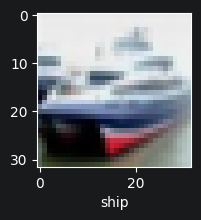

In [19]:
plot_sample(X_test, y_test, 1)

In [20]:
y_pred = cnn.predict(X_test)
y_pred[:5]

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


array([[1.24216871e-03, 7.00397641e-06, 4.31294134e-03, 8.75706434e-01,
        3.70771950e-03, 1.00757554e-01, 8.79140571e-03, 2.11136721e-04,
        5.26082655e-03, 2.76988999e-06],
       [1.56615563e-02, 5.74342012e-02, 2.56811927e-06, 6.52660447e-07,
        2.93635117e-06, 7.14419670e-08, 2.21264500e-08, 9.44704137e-09,
        9.24400389e-01, 2.49752868e-03],
       [1.73507869e-01, 2.04337880e-01, 2.42623985e-02, 1.68395732e-02,
        1.27876867e-02, 9.72641818e-03, 1.55584610e-04, 8.50011711e-04,
        3.95955145e-01, 1.61577508e-01],
       [7.91707873e-01, 3.37843620e-03, 1.43546894e-01, 1.23981596e-03,
        7.62221823e-03, 1.80529925e-04, 1.50201071e-04, 4.22915735e-04,
        5.14468588e-02, 3.04162386e-04],
       [6.37911368e-09, 1.11592428e-07, 5.05318632e-03, 1.95492338e-02,
        3.58215034e-01, 6.03573164e-04, 6.16578579e-01, 9.80219710e-08,
        1.26625750e-07, 1.21470176e-08]], dtype=float32)

In [21]:
y_pred_classes = [np.argmax(element) for element in y_pred]

In [22]:
y_pred_classes[:5]

[np.int64(3), np.int64(8), np.int64(8), np.int64(0), np.int64(6)]

In [23]:
y_test[:5]

array([3, 8, 8, 0, 6], dtype=uint8)

In [24]:
print(classification_report(y_test, y_pred_classes))

              precision    recall  f1-score   support

           0       0.78      0.73      0.75      1000
           1       0.83      0.78      0.80      1000
           2       0.62      0.56      0.59      1000
           3       0.57      0.43      0.49      1000
           4       0.55      0.73      0.63      1000
           5       0.54      0.69      0.61      1000
           6       0.85      0.69      0.76      1000
           7       0.71      0.77      0.74      1000
           8       0.81      0.78      0.80      1000
           9       0.77      0.79      0.78      1000

    accuracy                           0.69     10000
   macro avg       0.70      0.69      0.69     10000
weighted avg       0.70      0.69      0.69     10000

